# EV Customer Prioritization
## Data Understanding and Cleaning

**Course:** MSBA265 — Business Analytics Topics, Fall 2026  
**Student:** Nu Quynh Chau Nguyen  
**Dataset:** Kaggle Playground Series, Season 6 Episode 9  
**Notebook version:** October 9, 2026

This notebook explains the supplied data, checks its quality, documents conservative
cleaning decisions, and explores patterns before any predictive model is trained.
It is an initial AI-assisted analysis draft for the student to review, explain, and
refine before submission.

### The proposed business question

Which customers should an EV dealership prioritize for contact when its outreach capacity is limited?

The planned application is a **customer-prioritization prototype**. A synthetic
profile is the unit of analysis; a row is not an identified dealership customer.
The dataset does not contain campaign responses or sales transactions that would
let us measure actual outreach effectiveness.

### Source and meaning of the outcome

- [Official competition overview](https://www.kaggle.com/competitions/playground-series-s6e9/overview)
- [Official data page](https://www.kaggle.com/competitions/playground-series-s6e9/data)

Kaggle describes the goal as **Predicting Electric Vehicle Interest**, evaluates
predicted probabilities with ROC-AUC, and describes the Playground series' use of
synthetic data. The supplied target is named **Will_Buy_EV**. We use that label as
provided; we do not interpret it as verified purchases within a documented future
time window. The exact source generator and a complete survey codebook have not
been independently verified here.

### Reading guide

1. Files and first observations
2. Variable meanings and data quality
3. Cleaning decisions and exported data
4. Target balance and feature distributions
5. Descriptive relationships with the target
6. Train/test compatibility and limitations
7. What we learned and what comes next

Saved outputs can be read without running the code. To rerun, use the full project
folder, which contains the raw CSVs, or retrieve them using the included download
script. Setup and execution instructions are in the project README.

## 1. Set up a reproducible analysis

We use relative project paths, keep the raw files separate from processed outputs,
and use the same column names in train and test. Data-dependent preprocessing such
as scaling, imputation statistics, and feature encoding will be fitted within
training folds in the later modeling notebook.

In [1]:
from pathlib import Path
import os
import tempfile
import hashlib
import json
import platform
import importlib.metadata

# Keep plotting caches in a temporary directory rather than the raw-data folder.
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "ev_eda_matplotlib"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

%matplotlib inline

def find_project_root():
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "train.csv").is_file() and (candidate / "test.csv").is_file():
            return candidate
    raise FileNotFoundError(
        "Run this notebook from the complete EV project folder. "
        "The README explains how to obtain the raw CSVs."
    )

ROOT = find_project_root()
PROCESSED = ROOT / "data" / "processed"
TABLES = ROOT / "docs" / "reports" / "tables"
FIGURES = ROOT / "docs" / "reports" / "figures"
for folder in [PROCESSED, TABLES, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)

TARGET = "Will_Buy_EV"
NUMERIC = [
    "Age", "Annual_Income_USD", "Daily_Commute_km", "Number_of_Cars_Owned",
    "Charging_Stations_Near_Home", "Charging_Stations_Near_Work",
    "Environmental_Concern_Level",
]
CATEGORY_ORDER = {
    "Gender": ["Female", "Male", "Other"],
    "City_Type": ["Urban", "Suburban", "Rural"],
    "Current_Car_Type": ["Sedan", "SUV", "Hatchback", "Truck"],
    "Home_Charging_Possible": ["No", "Yes"],
    "Subsidy_Available": ["No", "Yes"],
    "Range_Anxiety_Level": ["Low", "Medium", "High"],
}
CATEGORICAL = list(CATEGORY_ORDER)
FEATURES = NUMERIC + CATEGORICAL

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 30)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 12,
    "axes.labelsize": 10, "figure.dpi": 110, "savefig.dpi": 160,
})
BLUE, TEAL, GREY = "#27679b", "#168c86", "#718096"

def show_table(frame, decimals=2):
    display(
        frame.style.hide(axis="index")
        .format(precision=decimals, thousands=",", na_rep="Not applicable")
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "left"), ("background", "#eef4f8")]},
            {"selector": "td", "props": [("text-align", "left"), ("white-space", "normal"),
                                        ("max-width", "330px"), ("padding", "7px")]},
        ])
    )

def save_figure(fig, filename):
    fig.savefig(FIGURES / filename, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

packages = ["pandas", "numpy", "matplotlib", "seaborn", "nbformat", "nbclient", "nbconvert", "ipykernel"]
versions = {name: importlib.metadata.version(name) for name in packages}
print("Python:", platform.python_version())
show_table(pd.DataFrame(versions.items(), columns=["Package", "Version"]))

Matplotlib is building the font cache; this may take a moment.


Python: 3.13.9


Package,Version
pandas,2.2.3
numpy,2.3.5
matplotlib,3.11.2
seaborn,0.13.2
nbformat,5.11.1
nbclient,0.11.0
nbconvert,7.17.1
ipykernel,7.4.0


## 2. Load and explain the three files

- **train.csv:** labeled profiles used for EDA and later model development.
- **test.csv:** profiles without the outcome. It can be used for schema checks and
  future predictions, but cannot independently measure prediction accuracy.
- **sample_submission.csv:** an example of the required prediction-file format.
  Its probability values are placeholders, not observed test outcomes.

We explicitly verify columns and ID alignment before using the files.

In [2]:
train_raw = pd.read_csv(ROOT / "train.csv")
test_raw = pd.read_csv(ROOT / "test.csv")
submission = pd.read_csv(ROOT / "sample_submission.csv")

assert train_raw.columns.is_unique and test_raw.columns.is_unique
assert set(train_raw.columns) == {"id", *FEATURES, TARGET}
assert set(test_raw.columns) == {"id", *FEATURES}
assert list(test_raw.columns) == [c for c in train_raw.columns if c != TARGET]
assert list(submission.columns) == ["id", TARGET]
assert submission["id"].equals(test_raw["id"])
assert set(train_raw[TARGET].unique()) == {"No", "Yes"}

raw_frames = {"train.csv": train_raw, "test.csv": test_raw, "sample_submission.csv": submission}
file_summary = pd.DataFrame([
    {
        "File": name, "Records": len(frame), "Columns": frame.shape[1],
        "Observed outcome available": name == "train.csv",
        "First id": frame["id"].min(), "Last id": frame["id"].max(),
        "Memory (MB)": frame.memory_usage(deep=True).sum() / 1024**2,
    }
    for name, frame in raw_frames.items()
])
file_summary.to_csv(TABLES / "file_summary.csv", index=False)
raw_hashes = {name: sha256_file(ROOT / name) for name in raw_frames}
show_table(file_summary)
display(train_raw.head(5))

File,Records,Columns,Observed outcome available,First id,Last id,Memory (MB)
train.csv,"668,665",15,True,0,"668,664",276.47
test.csv,"286,571",14,False,"668,665","955,235",104.50
sample_submission.csv,"286,571",2,False,"668,665","955,235",4.37


,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,0,66,92887.0,23.4,2,3,7,1.0,Male,Suburban,Sedan,Yes,No,Low,No
1,1,38,30000.0,5.0,1,2,2,4.0,Male,Rural,SUV,Yes,No,Low,No
2,2,26,94389.0,36.8,1,8,15,5.0,Female,Urban,Sedan,No,Yes,Low,Yes
3,3,66,73580.0,23.7,2,6,9,3.0,Male,Suburban,Hatchback,Yes,No,Low,No
4,4,54,57898.0,50.8,1,2,3,3.0,Male,Suburban,Hatchback,Yes,No,Low,No


In [3]:
template_summary = pd.DataFrame([{
    "Test IDs aligned": submission["id"].equals(test_raw["id"]),
    "Unique template probabilities": submission[TARGET].nunique(),
    "Minimum template probability": submission[TARGET].min(),
    "Maximum template probability": submission[TARGET].max(),
    "All probabilities in [0, 1]": submission[TARGET].between(0, 1).all(),
}])
show_table(template_summary, decimals=6)

Test IDs aligned,Unique template probabilities,Minimum template probability,Maximum template probability,"All probabilities in [0, 1]"
True,1,0.174645,0.174645,True


**Interpretation:** the train file contains one ID, thirteen candidate predictors,
and one target. The test file contains the same candidate predictors and no target.
Repeated probability values in the submission template are intentional; they are
not duplicate customer profiles and should not be deleted.

An ID is useful for tracing records and matching predictions. Its row sequence is
not evidence of time or a geographic location, so it is excluded from the predictor
set.

## 3. Business data dictionary

Descriptions below combine column names with values observed in the files.
Qualifications identify information that the available source does not establish.
An observed range is a description of this dataset, not a universal eligibility or
validity rule.

In [4]:
definitions = {
    "id": ("Identifier", "Integer", "Unique synthetic-profile row identifier.",
           "Keep for traceability; exclude from model predictors."),
    "Age": ("Predictor", "Numeric age", "Recorded age, interpreted as years.",
            "The data do not establish a broader customer-age eligibility rule."),
    "Annual_Income_USD": ("Predictor", "Numeric; USD/year", "Recorded annual income in US dollars.",
                         "Country, income definition, and individual-versus-household basis are unspecified."),
    "Daily_Commute_km": ("Predictor", "Numeric; km/day", "Recorded daily commuting distance.",
                        "One-way versus round-trip distance is unspecified."),
    "Number_of_Cars_Owned": ("Predictor", "Count", "Recorded count of cars owned.",
                            "Person-versus-household ownership unit is unspecified."),
    "Charging_Stations_Near_Home": ("Predictor", "Count", "Recorded stations near home.",
                                   "The meaning of 'near' and station-versus-connector counting are unspecified."),
    "Charging_Stations_Near_Work": ("Predictor", "Count", "Recorded stations near work.",
                                   "The meaning of 'near' and station-versus-connector counting are unspecified."),
    "Environmental_Concern_Level": ("Predictor", "Coded level", "Recorded environmental-concern code, observed 1–5.",
                                     "Survey anchors and exact scale direction are not independently verified."),
    "Gender": ("Predictor candidate", "Nominal category", "Recorded Female, Male, or Other category.",
               "Consider business necessity and subgroup performance before model inclusion."),
    "City_Type": ("Predictor", "Nominal category", "Recorded Urban, Suburban, or Rural area category.",
                  "Geographic definitions and country are unspecified."),
    "Current_Car_Type": ("Predictor", "Nominal category", "Recorded Sedan, SUV, Hatchback, or Truck category.",
                         "Fuel type, age, make, and whether this is a primary vehicle are unspecified."),
    "Home_Charging_Possible": ("Predictor", "Binary category", "Recorded Yes/No home-charging possibility.",
                              "Installed equipment, capacity, charging speed, and cost are unspecified."),
    "Subsidy_Available": ("Predictor", "Binary category", "Recorded Yes/No subsidy availability.",
                         "Program, jurisdiction, eligibility, and amount are unspecified."),
    "Range_Anxiety_Level": ("Predictor", "Ordered category", "Recorded Low, Medium, or High range-anxiety category.",
                           "Survey definition and category thresholds are unspecified."),
    "Will_Buy_EV": ("Target", "Binary outcome label", "Supplied No/Yes outcome; cleaned mapping is No=0, Yes=1.",
                    "No verified transaction information or prediction time horizon is supplied."),
}

def observed_values(frame, column):
    if column not in frame:
        return "Not present"
    series = frame[column]
    if pd.api.types.is_numeric_dtype(series):
        if series.mod(1).eq(0).all():
            return f"{series.min():,.0f} to {series.max():,.0f}"
        return f"{series.min():,.1f} to {series.max():,.1f}"
    return ", ".join(str(value) for value in sorted(series.dropna().unique()))

dictionary = pd.DataFrame([
    {
        "Column": column, "Role": definitions[column][0],
        "Logical type / unit": definitions[column][1],
        "Meaning": definitions[column][2],
        "Observed train values": observed_values(train_raw, column),
        "Observed test values": observed_values(test_raw, column),
        "Qualification / decision": definitions[column][3],
    }
    for column in train_raw.columns
])
dictionary.to_csv(TABLES / "data_dictionary.csv", index=False)
show_table(dictionary[["Column", "Logical type / unit", "Meaning", "Observed train values"]])
show_table(dictionary[["Column", "Qualification / decision"]])

Column,Logical type / unit,Meaning,Observed train values
id,Integer,Unique synthetic-profile row identifier.,"0 to 668,664"
Age,Numeric age,"Recorded age, interpreted as years.",25 to 69
Annual_Income_USD,Numeric; USD/year,Recorded annual income in US dollars.,"30,000 to 188,549"
Daily_Commute_km,Numeric; km/day,Recorded daily commuting distance.,5.0 to 98.7
Number_of_Cars_Owned,Count,Recorded count of cars owned.,1 to 4
Charging_Stations_Near_Home,Count,Recorded stations near home.,0 to 14
Charging_Stations_Near_Work,Count,Recorded stations near work.,0 to 19
Environmental_Concern_Level,Coded level,"Recorded environmental-concern code, observed 1–5.",1 to 5
Gender,Nominal category,"Recorded Female, Male, or Other category.","Female, Male, Other"
City_Type,Nominal category,"Recorded Urban, Suburban, or Rural area category.","Rural, Suburban, Urban"


Column,Qualification / decision
id,Keep for traceability; exclude from model predictors.
Age,The data do not establish a broader customer-age eligibility rule.
Annual_Income_USD,"Country, income definition, and individual-versus-household basis are unspecified."
Daily_Commute_km,One-way versus round-trip distance is unspecified.
Number_of_Cars_Owned,Person-versus-household ownership unit is unspecified.
Charging_Stations_Near_Home,The meaning of 'near' and station-versus-connector counting are unspecified.
Charging_Stations_Near_Work,The meaning of 'near' and station-versus-connector counting are unspecified.
Environmental_Concern_Level,Survey anchors and exact scale direction are not independently verified.
Gender,Consider business necessity and subgroup performance before model inclusion.
City_Type,Geographic definitions and country are unspecified.


## 4. Audit data quality before changing anything

The checks distinguish missing cells, blank text, whitespace inconsistencies,
duplicate IDs, repeated full rows, and repeated predictor profiles. Expected
categories describe this competition snapshot; they are not claimed as a complete
codebook for every real-world customer.

We also check non-finite numbers, nonnegative age/income/distance/counts, integer
representations for count/code fields, and the observed concern-code vocabulary.
Zero charging stations is a valid observed value, not a missing-data code.

In [5]:
quality_rows = []
integer_fields = [
    "id", "Age", "Number_of_Cars_Owned", "Charging_Stations_Near_Home",
    "Charging_Stations_Near_Work", "Environmental_Concern_Level",
]
nonnegative_fields = [
    "Age", "Annual_Income_USD", "Daily_Commute_km", "Number_of_Cars_Owned",
    "Charging_Stations_Near_Home", "Charging_Stations_Near_Work",
]
for name, frame in {"train.csv": train_raw, "test.csv": test_raw}.items():
    text_cols = frame.select_dtypes(include=["object", "string"]).columns
    numeric_cols = frame.select_dtypes(include=np.number).columns
    checks = {
        "Missing cells": int(frame.isna().sum().sum()),
        "Empty/whitespace-only text cells": sum(int(frame[c].str.strip().eq("").sum()) for c in text_cols),
        "Text cells with boundary whitespace": sum(int(frame[c].ne(frame[c].str.strip()).sum()) for c in text_cols),
        "Duplicate IDs": int(frame["id"].duplicated().sum()),
        "Duplicate full rows": int(frame.duplicated().sum()),
        "Repeated predictor profiles (exclude ID and target)": int(frame[FEATURES].duplicated().sum()),
        "Non-finite numeric cells": int((~np.isfinite(frame[numeric_cols].to_numpy())).sum()),
        "Negative values in nonnegative fields": sum(int(frame[c].lt(0).sum()) for c in nonnegative_fields),
        "Non-integer values in integer/count/code fields": sum(int(frame[c].mod(1).ne(0).sum()) for c in integer_fields),
        "Unexpected categorical values": sum(int((~frame[c].isin(values)).sum()) for c, values in CATEGORY_ORDER.items()),
        "Concern codes outside observed 1–5 vocabulary": int((~frame["Environmental_Concern_Level"].isin([1, 2, 3, 4, 5])).sum()),
    }
    for check, count in checks.items():
        quality_rows.append({"Dataset": name, "Check": check, "Flagged cells/rows": count})

quality = pd.DataFrame(quality_rows)
quality.to_csv(TABLES / "data_quality_audit.csv", index=False)
show_table(quality.pivot(index="Check", columns="Dataset", values="Flagged cells/rows").reset_index(), 0)
# Repeated predictor profiles can be legitimate and remain a diagnostic.
critical_checks = quality.loc[
    ~quality["Check"].eq("Repeated predictor profiles (exclude ID and target)")
]
assert critical_checks["Flagged cells/rows"].eq(0).all(), "Review the flagged issues before exporting clean data."

id_checks = pd.DataFrame([
    {
        "Dataset": name,
        "IDs unique": frame["id"].is_unique,
        "IDs increasing": frame["id"].is_monotonic_increasing,
        "IDs sequential within file": frame["id"].diff().iloc[1:].eq(1).all(),
    }
    for name, frame in raw_frames.items()
])
assert not train_raw["id"].isin(test_raw["id"]).any()
show_table(id_checks)
print("Train and test IDs do not overlap. Submission IDs match test in the same order.")

Check,test.csv,train.csv
Concern codes outside observed 1–5 vocabulary,0,0
Duplicate IDs,0,0
Duplicate full rows,0,0
Empty/whitespace-only text cells,0,0
Missing cells,0,0
Negative values in nonnegative fields,0,0
Non-finite numeric cells,0,0
Non-integer values in integer/count/code fields,0,0
Repeated predictor profiles (exclude ID and target),0,0
Text cells with boundary whitespace,0,0


Dataset,IDs unique,IDs increasing,IDs sequential within file
train.csv,True,True,True
test.csv,True,True,True
sample_submission.csv,True,True,True


Train and test IDs do not overlap. Submission IDs match test in the same order.


## 5. Inspect statistical outliers and unusual concentrations

A boxplot or IQR flag identifies an unusual observation relative to a distribution;
it does not establish an input error. We inspect these flags rather than
automatically deleting them. Four cars owned, high income, or a long commute can
be valid values in the supplied data.

In [6]:
numeric_summary = train_raw[NUMERIC].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
).T.reset_index(names="Feature")
numeric_summary["Skewness"] = train_raw[NUMERIC].skew().reindex(numeric_summary["Feature"]).to_numpy()
numeric_summary.to_csv(TABLES / "numeric_summary.csv", index=False)
show_table(numeric_summary)

outlier_rows = []
for column in NUMERIC:
    values = train_raw[column]
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flag = values.lt(lower) | values.gt(upper)
    outlier_rows.append({
        "Feature": column, "Q1": q1, "Q3": q3, "Lower IQR fence": lower,
        "Upper IQR fence": upper, "Flagged train records": int(flag.sum()),
        "Flagged share (%)": flag.mean() * 100,
        "Decision": "Retain; statistical flag alone does not establish an error",
    })
outliers = pd.DataFrame(outlier_rows)
outliers.to_csv(TABLES / "iqr_outlier_audit.csv", index=False)
show_table(outliers)

Feature,count,mean,std,min,1%,25%,50%,75%,99%,max,Skewness
Age,"668,665.00",47.04,12.88,25.00,25.00,36.00,47.00,58.00,69.00,69.00,-0.00
Annual_Income_USD,"668,665.00","84,769.27","28,648.03","30,000.00","30,000.00","67,376.00","84,880.00","102,753.00","151,159.00","188,549.00",-0.01
Daily_Commute_km,"668,665.00",32.16,18.73,5.00,5.00,17.20,33.60,47.40,68.50,98.70,-0.08
Number_of_Cars_Owned,"668,665.00",1.71,0.73,1.00,1.00,1.00,2.00,2.00,4.00,4.00,0.81
Charging_Stations_Near_Home,"668,665.00",4.96,3.93,0.00,0.00,2.00,4.00,7.00,14.00,14.00,0.70
Charging_Stations_Near_Work,"668,665.00",7.18,5.19,0.00,0.00,3.00,6.00,10.00,19.00,19.00,0.70
Environmental_Concern_Level,"668,665.00",2.94,1.43,1.00,1.00,2.00,3.00,4.00,5.00,5.00,0.05


Feature,Q1,Q3,Lower IQR fence,Upper IQR fence,Flagged train records,Flagged share (%),Decision
Age,36.00,58.00,3.00,91.00,0,0.00,Retain; statistical flag alone does not establish an error
Annual_Income_USD,"67,376.00","102,753.00","14,310.50","155,818.50","3,678",0.55,Retain; statistical flag alone does not establish an error
Daily_Commute_km,17.20,47.40,-28.10,92.70,41,0.01,Retain; statistical flag alone does not establish an error
Number_of_Cars_Owned,1.00,2.00,-0.50,3.50,"13,489",2.02,Retain; statistical flag alone does not establish an error
Charging_Stations_Near_Home,2.00,7.00,-5.50,14.50,0,0.00,Retain; statistical flag alone does not establish an error
Charging_Stations_Near_Work,3.00,10.00,-7.50,20.50,0,0.00,Retain; statistical flag alone does not establish an error
Environmental_Concern_Level,2.00,4.00,-1.00,7.00,0,0.00,Retain; statistical flag alone does not establish an error


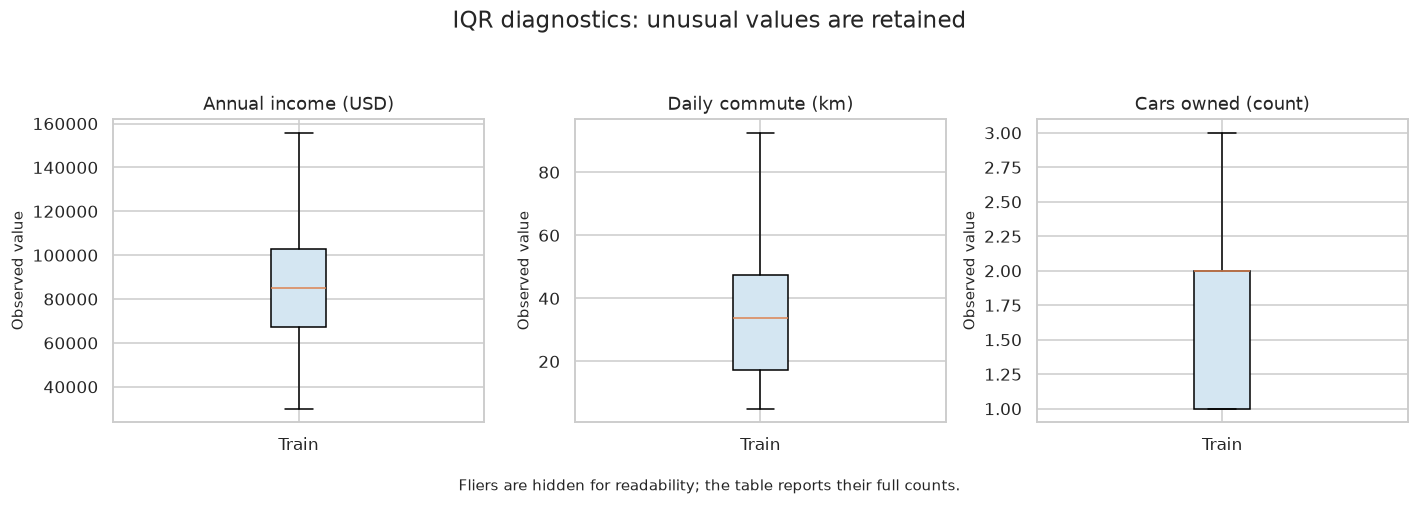

**Observed concentration:** 61,605 training records (9.21%) have annual income exactly USD 30,000. The commute value 5 km also occurs in 144,280 records (21.58%). The CSV does not establish why these concentrations exist, so both are preserved. Test contains 2 commute values above the training maximum of 98.7 km. They are outside the observed training range, not automatically invalid values.

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
box_features = ["Annual_Income_USD", "Daily_Commute_km", "Number_of_Cars_Owned"]
box_labels = ["Annual income (USD)", "Daily commute (km)", "Cars owned (count)"]
for ax, column, label in zip(axes, box_features, box_labels):
    ax.boxplot(train_raw[column], tick_labels=["Train"], showfliers=False,
               patch_artist=True, boxprops={"facecolor": "#d4e6f2"})
    ax.set_title(label)
    ax.set_ylabel("Observed value")
fig.suptitle("IQR diagnostics: unusual values are retained", fontsize=15)
fig.text(0.5, 0.01, "Fliers are hidden for readability; the table reports their full counts.",
         ha="center", fontsize=10)
fig.tight_layout(rect=[0, 0.05, 1, 0.92])
save_figure(fig, "01_outlier_diagnostics.png")

income_floor_rows = int(train_raw["Annual_Income_USD"].eq(30000).sum())
income_floor_share = income_floor_rows / len(train_raw) * 100
commute_floor_rows = int(train_raw["Daily_Commute_km"].eq(5).sum())
commute_floor_share = commute_floor_rows / len(train_raw) * 100
max_train_commute = train_raw["Daily_Commute_km"].max()
commute_beyond_train = int(test_raw["Daily_Commute_km"].gt(max_train_commute).sum())
display(Markdown(
    f"**Observed concentration:** {income_floor_rows:,} training records "
    f"({income_floor_share:.2f}%) have annual income exactly USD 30,000. "
    f"The commute value 5 km also occurs in {commute_floor_rows:,} records "
    f"({commute_floor_share:.2f}%). The CSV does not establish why these "
    "concentrations exist, so both are preserved. "
    f"Test contains {commute_beyond_train} commute values above the training maximum "
    f"of {max_train_commute:.1f} km. They are outside the observed training range, "
    "not automatically invalid values."
))

## 6. Clean conservatively and document every action

The audit found no missing values, duplicate IDs, malformed categories, or checked
domain defects. Therefore, no observations are removed and no values are imputed.
All observed numeric values and legitimate zeros are retained.

Our preparation is limited to:

1. Making clean copies and checking/stripping categorical boundary whitespace.
2. Storing exactly integer-valued income and concern codes as integers, after
   verifying the casts are lossless. Income remains a numeric money measure.
3. Explicitly mapping the train target from **No → 0** and **Yes → 1**.
4. Retaining ID for traceability while excluding it from the predictor list.

The test file remains unlabeled. Category encoding, scaling, class balancing,
feature selection, and modeling are reserved for the next phase.

In [8]:
train_clean, test_clean = train_raw.copy(), test_raw.copy()
cleaning_log = []

for name, raw, clean in [
    ("train", train_raw, train_clean), ("test", test_raw, test_clean)
]:
    whitespace_changes = 0
    for column in CATEGORICAL:
        stripped = clean[column].str.strip()
        whitespace_changes += int(clean[column].ne(stripped).sum())
        clean[column] = stripped
    cleaning_log.append({
        "Dataset": name, "Action": "Check/strip categorical boundary whitespace",
        "Affected cells": whitespace_changes, "Rows removed": 0,
        "Reason": "Keep category labels consistent; none required value correction in this snapshot",
    })

    for column in ["Annual_Income_USD", "Environmental_Concern_Level"]:
        assert np.isfinite(clean[column]).all()
        assert clean[column].mod(1).eq(0).all()
        integer_values = clean[column].astype("int64")
        assert np.array_equal(clean[column].to_numpy(), integer_values.to_numpy())
        clean[column] = integer_values
        cleaning_log.append({
            "Dataset": name, "Action": f"Lossless integer storage: {column}",
            "Affected cells": len(clean), "Rows removed": 0,
            "Reason": "Storage representation changes; observed numeric values remain identical",
        })

TARGET_MAPPING = {"No": 0, "Yes": 1}
train_clean[TARGET] = train_raw[TARGET].map(TARGET_MAPPING).astype("int64")
cleaning_log.append({
    "Dataset": "train", "Action": "Target coding: No=0; Yes=1",
    "Affected cells": len(train_clean), "Rows removed": 0,
    "Reason": "Explicit reversible target representation for later classification",
})

for raw, clean in [(train_raw, train_clean), (test_raw, test_clean)]:
    assert len(raw) == len(clean)
    assert raw["id"].equals(clean["id"])
    assert np.array_equal(raw[NUMERIC].to_numpy(), clean[NUMERIC].to_numpy())
    assert raw[CATEGORICAL].equals(clean[CATEGORICAL])
    assert not clean.isna().any().any()
assert TARGET not in test_clean.columns
assert train_clean[TARGET].value_counts().to_dict() == {
    0: int(train_raw[TARGET].eq("No").sum()),
    1: int(train_raw[TARGET].eq("Yes").sum()),
}

train_clean.to_csv(PROCESSED / "train_clean.csv", index=False)
test_clean.to_csv(PROCESSED / "test_clean.csv", index=False)
log_table = pd.DataFrame(cleaning_log)
log_table.to_csv(TABLES / "cleaning_log.csv", index=False)
show_table(log_table)

Dataset,Action,Affected cells,Rows removed,Reason
train,Check/strip categorical boundary whitespace,0,0,Keep category labels consistent; none required value correction in this snapshot
train,Lossless integer storage: Annual_Income_USD,"668,665",0,Storage representation changes; observed numeric values remain identical
train,Lossless integer storage: Environmental_Concern_Level,"668,665",0,Storage representation changes; observed numeric values remain identical
test,Check/strip categorical boundary whitespace,0,0,Keep category labels consistent; none required value correction in this snapshot
test,Lossless integer storage: Annual_Income_USD,"286,571",0,Storage representation changes; observed numeric values remain identical
test,Lossless integer storage: Environmental_Concern_Level,"286,571",0,Storage representation changes; observed numeric values remain identical
train,Target coding: No=0; Yes=1,"668,665",0,Explicit reversible target representation for later classification


In [9]:
before_after = pd.DataFrame([
    {
        "Dataset": name, "Rows before": len(raw), "Rows after": len(clean),
        "Rows removed": len(raw) - len(clean),
        "Predictor values changed": 0, "Missing cells after": int(clean.isna().sum().sum()),
    }
    for name, raw, clean in [("Train", train_raw, train_clean), ("Test", test_raw, test_clean)]
])
show_table(before_after, 0)
type_changes = pd.DataFrame([
    {
        "Column": column, "Raw dtype": str(train_raw[column].dtype),
        "Clean dtype": str(train_clean[column].dtype),
        "Meaning": "Same numeric values" if column != TARGET else "No=0; Yes=1",
    }
    for column in ["Annual_Income_USD", "Environmental_Concern_Level", TARGET]
])
show_table(type_changes)
display(train_clean.head(5))
print("Saved data/processed/train_clean.csv and data/processed/test_clean.csv.")

Dataset,Rows before,Rows after,Rows removed,Predictor values changed,Missing cells after
Train,"668,665","668,665",0,0,0
Test,"286,571","286,571",0,0,0


Column,Raw dtype,Clean dtype,Meaning
Annual_Income_USD,float64,int64,Same numeric values
Environmental_Concern_Level,float64,int64,Same numeric values
Will_Buy_EV,object,int64,No=0; Yes=1


,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,0,66,92887,23.4,2,3,7,1,Male,Suburban,Sedan,Yes,No,Low,0
1,1,38,30000,5.0,1,2,2,4,Male,Rural,SUV,Yes,No,Low,0
2,2,26,94389,36.8,1,8,15,5,Female,Urban,Sedan,No,Yes,Low,1
3,3,66,73580,23.7,2,6,9,3,Male,Suburban,Hatchback,Yes,No,Low,0
4,4,54,57898,50.8,1,2,3,3,Male,Suburban,Hatchback,Yes,No,Low,0


Saved data/processed/train_clean.csv and data/processed/test_clean.csv.


## 7. Understand the target and the baseline

Every rate below uses the supplied training labels. We call it a **Yes-label
share**, not a measured dealership conversion rate. The large majority class makes
accuracy alone an inadequate description of a future model.

Label,Clean code,Records,Share (%)
No,0,"551,886",82.54
Yes,1,"116,779",17.46


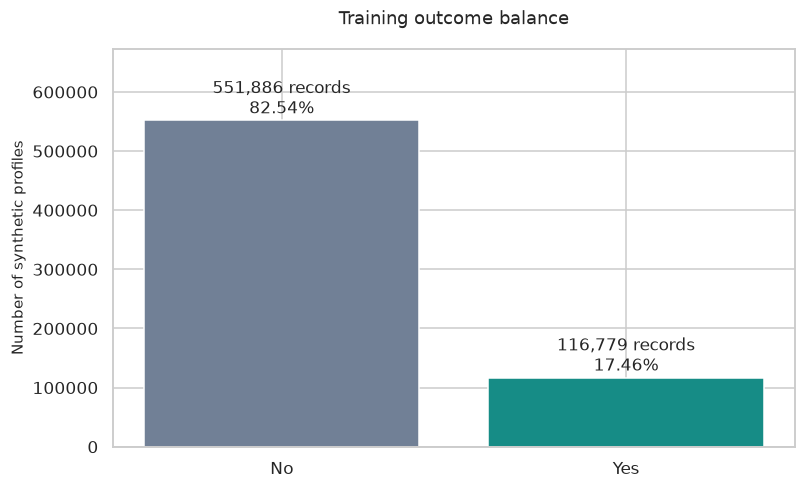

**Takeaway:** Yes represents **17.46%** of labels. An always-No rule achieves **82.54% accuracy** while detecting none of the Yes profiles. Later evaluation should include ranking quality (ROC-AUC), precision/recall, and how many Yes labels appear within an agreed outreach capacity. No predictive model has been fitted here.

In [10]:
target_counts = train_clean[TARGET].value_counts().reindex([0, 1])
target_summary = pd.DataFrame({
    "Label": ["No", "Yes"], "Clean code": [0, 1],
    "Records": target_counts.to_numpy(),
    "Share (%)": target_counts.to_numpy() / len(train_clean) * 100,
})
target_summary.to_csv(TABLES / "target_summary.csv", index=False)
show_table(target_summary)

positive_rate = train_clean[TARGET].mean()
fig, ax = plt.subplots(figsize=(8, 4.7))
bars = ax.bar(target_summary["Label"], target_summary["Records"], color=[GREY, TEAL])
for bar, count, share in zip(bars, target_summary["Records"], target_summary["Share (%)"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + len(train_clean)*0.018,
            f"{count:,} records\n{share:.2f}%", ha="center", fontsize=11)
ax.set_title("Training outcome balance", pad=16)
ax.set_ylabel("Number of synthetic profiles")
ax.set_ylim(0, target_counts.max()*1.22)
ax.ticklabel_format(axis="y", style="plain")
save_figure(fig, "02_target_balance.png")
display(Markdown(
    f"**Takeaway:** Yes represents **{positive_rate:.2%}** of labels. "
    f"An always-No rule achieves **{1-positive_rate:.2%} accuracy** while detecting "
    "none of the Yes profiles. Later evaluation should include ranking quality "
    "(ROC-AUC), precision/recall, and how many Yes labels appear within an agreed "
    "outreach capacity. No predictive model has been fitted here."
))

## 8. Inspect feature distributions

Histograms show numeric distributions before learned transformations. Counts and
coded levels use integer bins. We do not infer a mandatory transformation from
skewness alone; that choice will be evaluated inside a modeling pipeline.

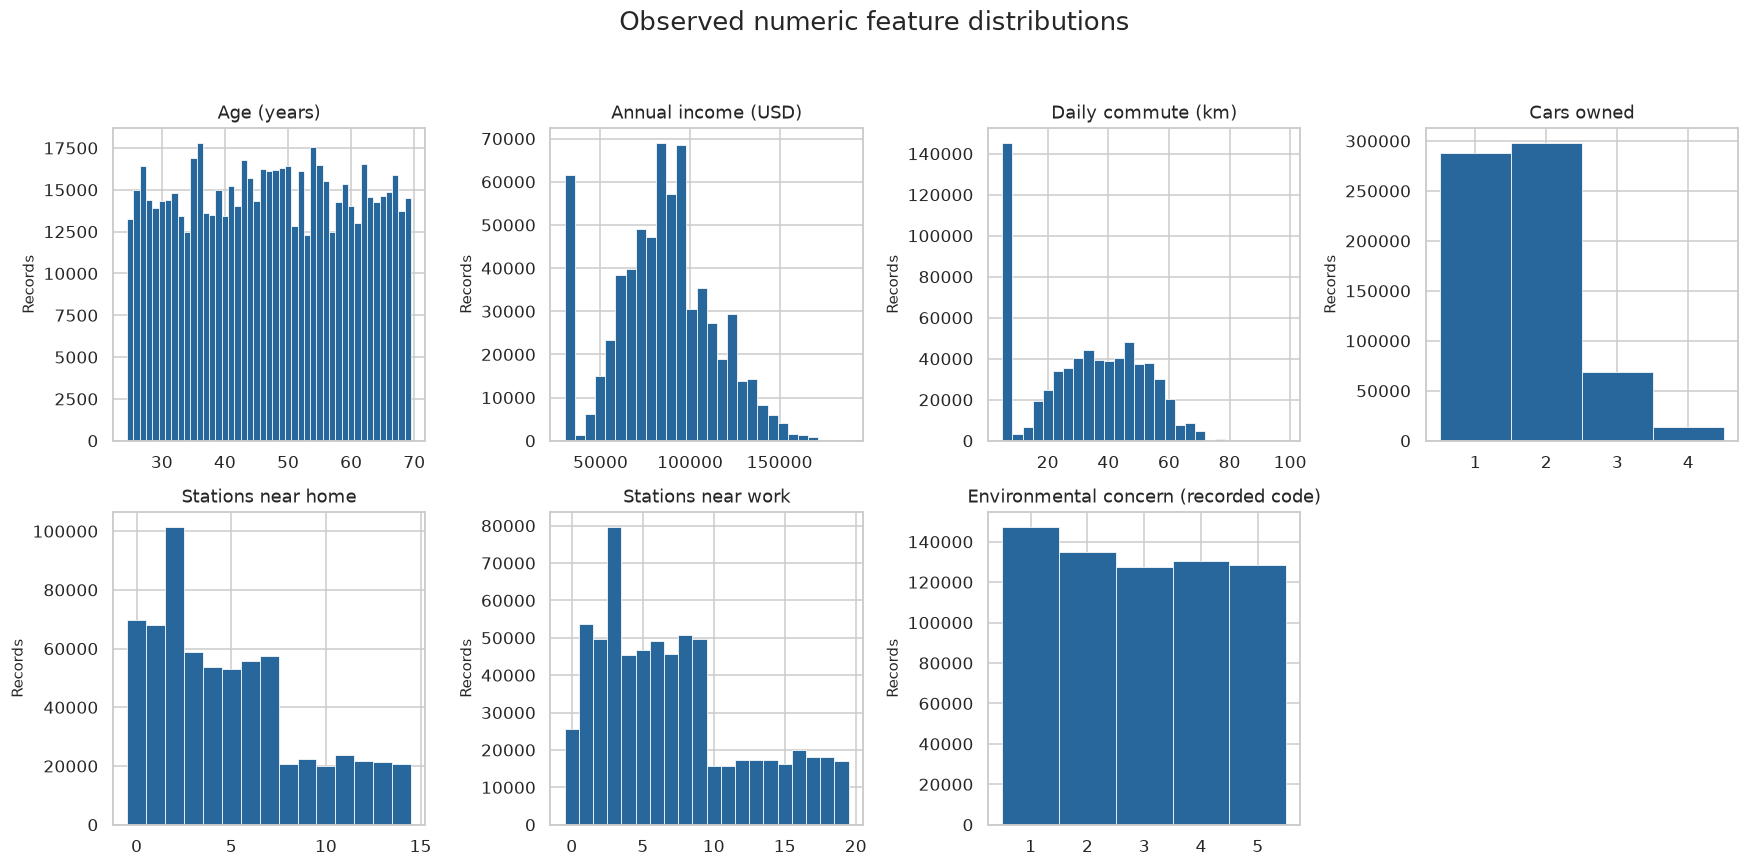

**Takeaway:** the supplied age range is 25–69 years and cars owned range from 1 to 4. These ranges limit what this snapshot can describe. It contains no car-free profiles. The income concentration at USD 30,000 is a property to document, not an established error.

In [11]:
titles = {
    "Age": "Age (years)", "Annual_Income_USD": "Annual income (USD)",
    "Daily_Commute_km": "Daily commute (km)", "Number_of_Cars_Owned": "Cars owned",
    "Charging_Stations_Near_Home": "Stations near home",
    "Charging_Stations_Near_Work": "Stations near work",
    "Environmental_Concern_Level": "Environmental concern (recorded code)",
}
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, column in zip(axes.flat, NUMERIC):
    values = train_clean[column]
    if column in ["Age", "Number_of_Cars_Owned", "Charging_Stations_Near_Home",
                  "Charging_Stations_Near_Work", "Environmental_Concern_Level"]:
        bins = np.arange(values.min()-0.5, values.max()+1.5)
    else:
        bins = 28
    ax.hist(values, bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
    ax.set_title(titles[column])
    ax.set_ylabel("Records")
    ax.ticklabel_format(axis="y", style="plain")
axes.flat[-1].axis("off")
fig.suptitle("Observed numeric feature distributions", fontsize=17)
fig.tight_layout(rect=[0, 0, 1, 0.94])
save_figure(fig, "03_numeric_distributions.png")
display(Markdown(
    f"**Takeaway:** the supplied age range is "
    f"{train_clean['Age'].min()}–{train_clean['Age'].max()} years and cars owned "
    f"range from {train_clean['Number_of_Cars_Owned'].min()} to "
    f"{train_clean['Number_of_Cars_Owned'].max()}. These ranges limit what this "
    "snapshot can describe. It contains no car-free profiles. The income "
    "concentration at USD 30,000 is a property to document, not an established error."
))

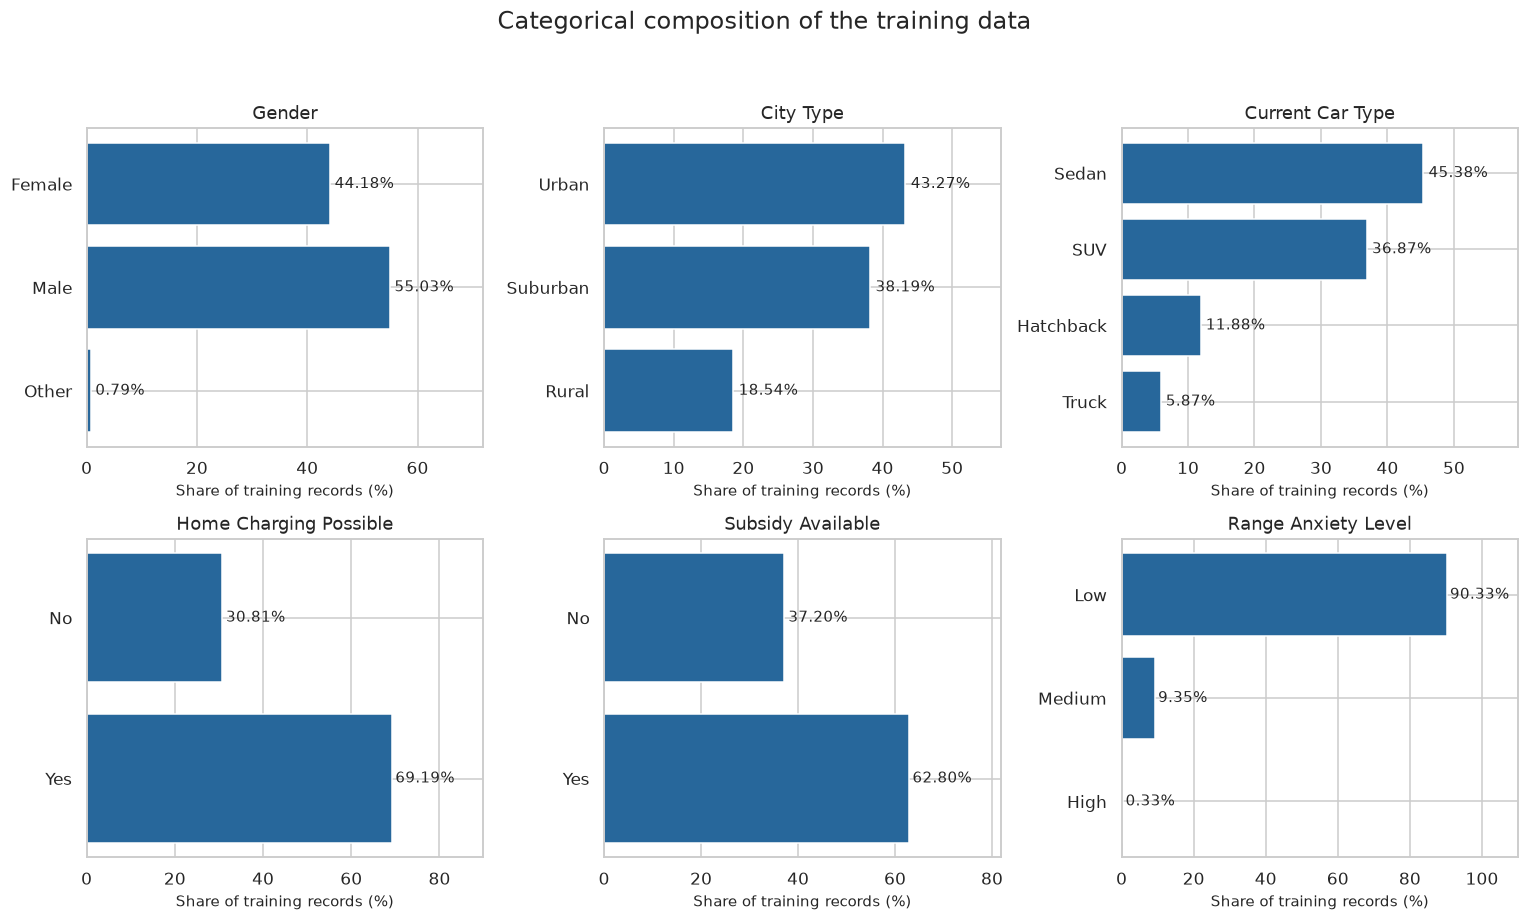

Feature,Category,Records,Share (%)
Gender,Other,"5,284",0.79
Range_Anxiety_Level,High,"2,194",0.33


**Takeaway:** some categories represent less than 1% of the data. We retain them and show their sample counts when interpreting subgroup outcomes. A low-frequency category is not automatically an invalid observation.

In [12]:
category_rows = []
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
for ax, column in zip(axes.flat, CATEGORICAL):
    counts = train_clean[column].value_counts().reindex(CATEGORY_ORDER[column], fill_value=0)
    shares = counts / len(train_clean) * 100
    ax.barh(shares.index, shares.to_numpy(), color=BLUE)
    ax.set_title(column.replace("_", " "))
    ax.set_xlabel("Share of training records (%)")
    ax.set_xlim(0, min(110, shares.max()*1.27 + 2))
    ax.invert_yaxis()
    for i, (category, share) in enumerate(shares.items()):
        ax.text(share + 0.8, i, f"{share:.2f}%", va="center", fontsize=10)
        category_rows.append({
            "Feature": column, "Category": category, "Records": int(counts[category]),
            "Share (%)": share,
        })
fig.suptitle("Categorical composition of the training data", fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.94])
save_figure(fig, "04_categorical_composition.png")
category_summary = pd.DataFrame(category_rows)
category_summary.to_csv(TABLES / "categorical_summary.csv", index=False)
rare_categories = category_summary.loc[category_summary["Share (%)"].lt(1)].copy()
show_table(rare_categories)
display(Markdown(
    "**Takeaway:** some categories represent less than 1% of the data. We retain "
    "them and show their sample counts when interpreting subgroup outcomes. "
    "A low-frequency category is not automatically an invalid observation."
))

## 9. Explore descriptive relationships with the target

Each group rate below is **Yes labels divided by all records in that group**.
Showing the denominator matters, especially for rare categories.
These are unadjusted associations in synthetic data. They do not establish causal
effects, show independent feature importance, or prove model performance.

Feature,Category,Records,Yes labels,Yes share (%)
Gender,Female,"295,427","52,480",17.76
Gender,Male,"367,954","63,381",17.23
Gender,Other,"5,284",918,17.37
City_Type,Urban,"289,305","46,595",16.11
City_Type,Suburban,"255,377","46,207",18.09
City_Type,Rural,"123,983","23,977",19.34
Current_Car_Type,Sedan,"303,459","52,185",17.20
Current_Car_Type,SUV,"246,545","44,613",18.10
Current_Car_Type,Hatchback,"79,438","13,846",17.43
Current_Car_Type,Truck,"39,223","6,135",15.64


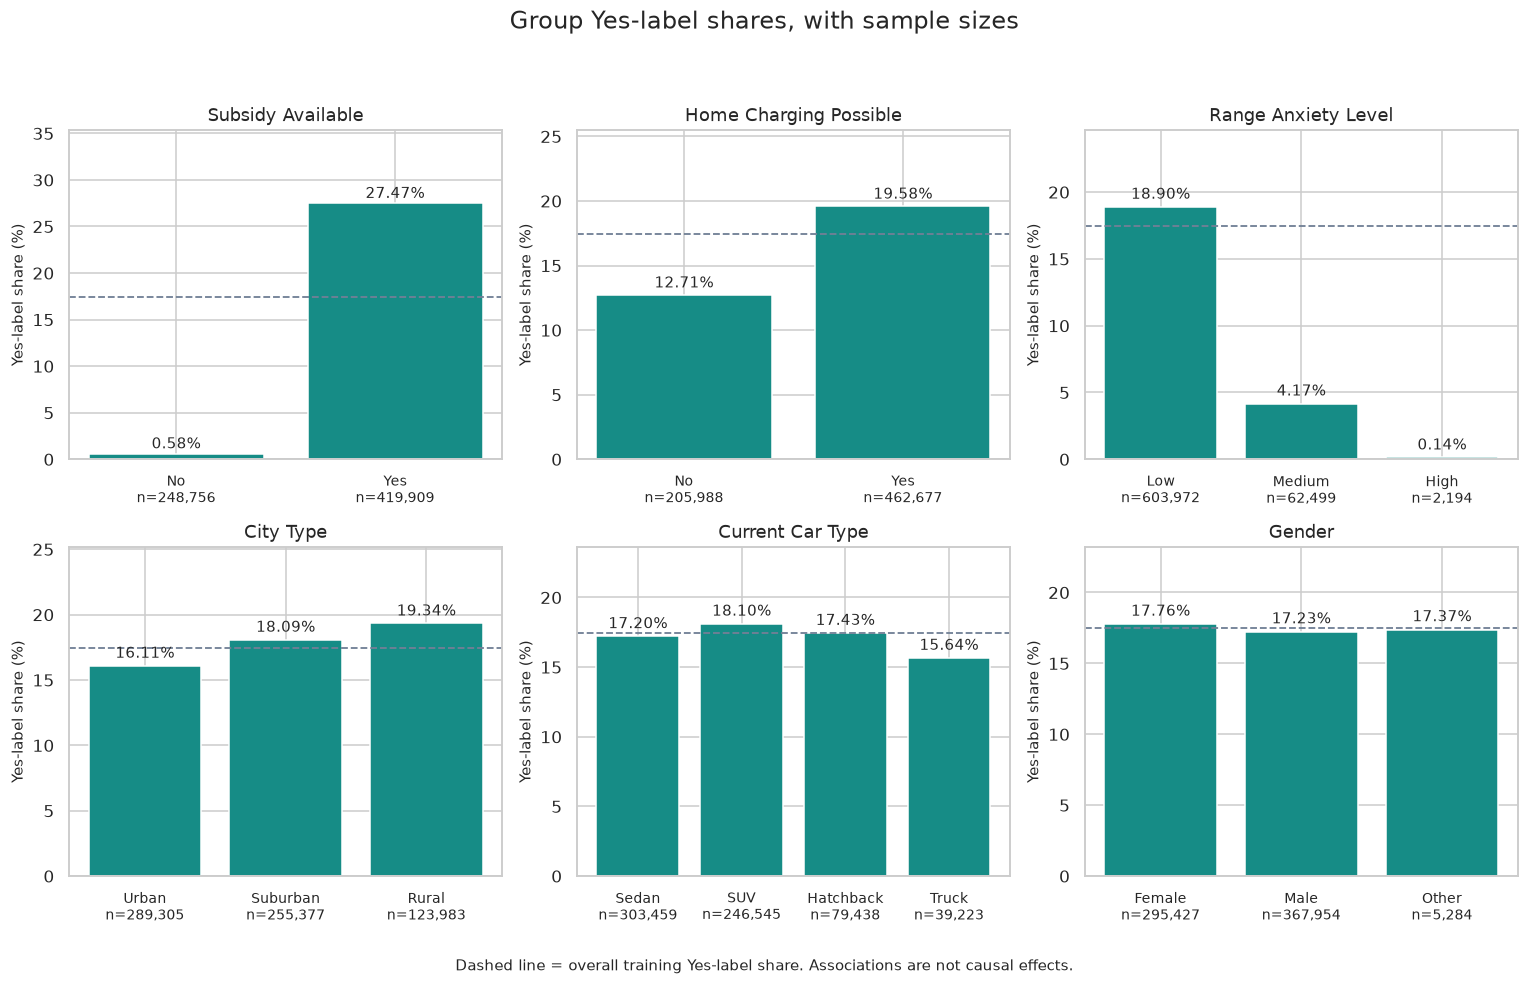

**Takeaways:**

- Subsidy available: 27.47% Yes labels; no subsidy: 0.58%.
- Home charging possible: 19.58%; not possible: 12.71%.
- High range anxiety includes only 3 Yes labels among 2,194 profiles.

These patterns motivate questions for later validation; they do not show that supplying a subsidy or a charger would cause a specific change in buying.

In [13]:
association_frames = []
for column in CATEGORICAL:
    group = train_clean.groupby(column, observed=True)[TARGET].agg(
        Records="size", Yes_labels="sum", Yes_share="mean"
    ).reindex(CATEGORY_ORDER[column]).reset_index()
    group = group.rename(columns={column: "Category", "Yes_labels": "Yes labels"})
    group.insert(0, "Feature", column)
    group["Yes share (%)"] = group.pop("Yes_share") * 100
    association_frames.append(group)
associations = pd.concat(association_frames, ignore_index=True)
associations.to_csv(TABLES / "categorical_target_associations.csv", index=False)
show_table(associations)

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
plot_order = ["Subsidy_Available", "Home_Charging_Possible", "Range_Anxiety_Level",
              "City_Type", "Current_Car_Type", "Gender"]
for ax, column in zip(axes.flat, plot_order):
    part = associations.loc[associations["Feature"].eq(column)]
    positions = np.arange(len(part))
    rates = part["Yes share (%)"].to_numpy()
    ax.bar(positions, rates, color=TEAL)
    ax.axhline(positive_rate*100, color=GREY, linestyle="--", linewidth=1.2)
    labels = [f"{category}\nn={int(count):,}" for category, count
              in zip(part["Category"], part["Records"])]
    ax.set_xticks(positions, labels, fontsize=9)
    ax.set_ylabel("Yes-label share (%)")
    ax.set_title(column.replace("_", " "))
    ax.set_ylim(0, max(positive_rate*100, rates.max())*1.25 + 1)
    for i, rate in enumerate(rates):
        ax.text(i, rate + 0.6, f"{rate:.2f}%", ha="center", fontsize=10)
fig.suptitle("Group Yes-label shares, with sample sizes", fontsize=16)
fig.text(0.5, 0.01, "Dashed line = overall training Yes-label share. Associations are not causal effects.",
         ha="center", fontsize=10)
fig.tight_layout(rect=[0, 0.04, 1, 0.94])
save_figure(fig, "05_categorical_target_associations.png")

subsidy = associations.loc[associations["Feature"].eq("Subsidy_Available")].set_index("Category")
home = associations.loc[associations["Feature"].eq("Home_Charging_Possible")].set_index("Category")
anxiety = associations.loc[associations["Feature"].eq("Range_Anxiety_Level")].set_index("Category")
display(Markdown(
    "**Takeaways:**\n\n"
    f"- Subsidy available: {subsidy.loc['Yes', 'Yes share (%)']:.2f}% Yes labels; "
    f"no subsidy: {subsidy.loc['No', 'Yes share (%)']:.2f}%.\n"
    f"- Home charging possible: {home.loc['Yes', 'Yes share (%)']:.2f}%; "
    f"not possible: {home.loc['No', 'Yes share (%)']:.2f}%.\n"
    f"- High range anxiety includes only {int(anxiety.loc['High', 'Yes labels']):,} "
    f"Yes labels among {int(anxiety.loc['High', 'Records']):,} profiles.\n\n"
    "These patterns motivate questions for later validation; they do not show "
    "that supplying a subsidy or a charger would cause a specific change in buying."
))

### Concern codes and income groups

Environmental concern is treated here as a recorded code. Income deciles are
descriptive groups formed from the training file only; they are not a learned
model feature or a predefined commercial customer segment.

Environmental_Concern_Level,Records,Yes labels,Yes share (%)
1,"147,476",834,0.57
2,"135,133","2,889",2.14
3,"127,351","14,126",11.09
4,"130,469","32,467",24.88
5,"128,236","66,463",51.83


Income group,Income interval,Records,Yes labels,Yes share (%)
D1,"(29999.999, 45980.0]","66,942","2,978",4.45
D2,"(45980.0, 62671.0]","66,861","5,656",8.46
D3,"(62671.0, 71832.0]","66,834","7,126",10.66
D4,"(71832.0, 78915.0]","66,844","8,800",13.16
D5,"(78915.0, 84880.0]","66,977","10,454",15.61
D6,"(84880.0, 91619.0]","67,013","12,045",17.97
D7,"(91619.0, 96748.0]","66,616","13,168",19.77
D8,"(96748.0, 107798.0]","66,854","14,678",21.96
D9,"(107798.0, 122349.0]","66,970","19,357",28.90
D10,"(122349.0, 188549.0]","66,754","22,517",33.73


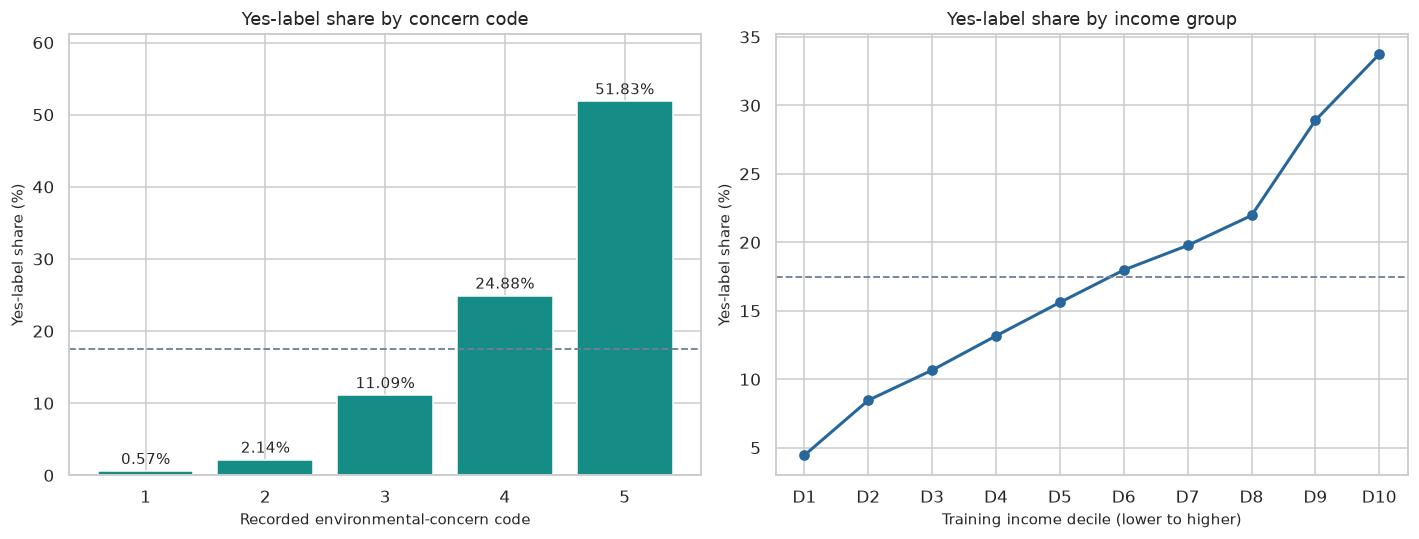

**Takeaway:** Yes-label shares increase across the recorded concern codes from 0.57% at code 1 to 51.83% at code 5. Income groups also provide descriptive hypotheses. We have not isolated independent effects or established how well a classifier will generalize.

In [14]:
concern = train_clean.groupby("Environmental_Concern_Level")[TARGET].agg(
    Records="size", Yes_labels="sum", Yes_share="mean"
).reset_index()
concern["Yes share (%)"] = concern.pop("Yes_share") * 100
concern = concern.rename(columns={"Yes_labels": "Yes labels"})
concern.to_csv(TABLES / "concern_target_associations.csv", index=False)

income_bins = pd.qcut(train_clean["Annual_Income_USD"], q=10, duplicates="drop")
income_groups = train_clean.groupby(income_bins, observed=True)[TARGET].agg(
    Records="size", Yes_labels="sum", Yes_share="mean"
).reset_index()
income_groups["Income group"] = [f"D{i}" for i in range(1, len(income_groups)+1)]
income_groups["Income interval"] = income_groups["Annual_Income_USD"].astype(str)
income_groups["Yes share (%)"] = income_groups.pop("Yes_share") * 100
income_groups = income_groups.rename(columns={"Yes_labels": "Yes labels"})
income_groups = income_groups[["Income group", "Income interval", "Records", "Yes labels", "Yes share (%)"]]
income_groups.to_csv(TABLES / "income_decile_target_associations.csv", index=False)
show_table(concern)
show_table(income_groups)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(concern["Environmental_Concern_Level"], concern["Yes share (%)"], color=TEAL)
axes[0].set_xticks([1, 2, 3, 4, 5])
axes[0].set_xlabel("Recorded environmental-concern code")
axes[0].set_title("Yes-label share by concern code")
for x, y in zip(concern["Environmental_Concern_Level"], concern["Yes share (%)"]):
    axes[0].text(x, y+1, f"{y:.2f}%", ha="center", fontsize=10)
axes[0].set_ylim(0, concern["Yes share (%)"].max()*1.18)
axes[1].plot(income_groups["Income group"], income_groups["Yes share (%)"],
             marker="o", color=BLUE, linewidth=2)
axes[1].set_xlabel("Training income decile (lower to higher)")
axes[1].set_title("Yes-label share by income group")
for ax in axes:
    ax.set_ylabel("Yes-label share (%)")
    ax.axhline(positive_rate*100, color=GREY, linestyle="--", linewidth=1.2)
fig.tight_layout()
save_figure(fig, "06_concern_and_income_associations.png")
display(Markdown(
    "**Takeaway:** Yes-label shares increase across the recorded concern codes "
    f"from {concern['Yes share (%)'].iloc[0]:.2f}% at code 1 to "
    f"{concern['Yes share (%)'].iloc[-1]:.2f}% at code 5. "
    "Income groups also provide descriptive hypotheses. We have not isolated "
    "independent effects or established how well a classifier will generalize."
))

## 10. Inspect numeric correlations

The matrix excludes ID. It includes the binary target solely as a descriptive
association check. Pearson correlation captures linear relationships; a small
coefficient does not establish that a feature is useless to every model.
Concern/count variables are coded numerically, so interpret their coefficients
with that representation in mind.

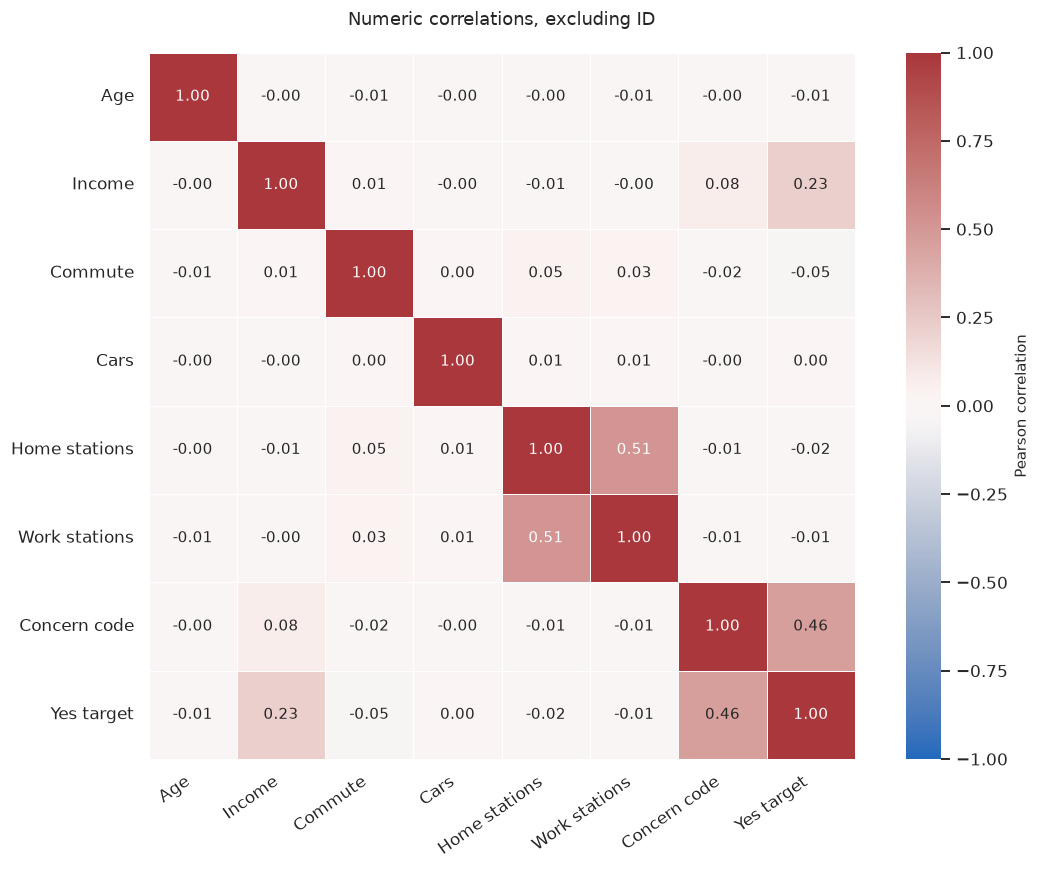

In [15]:
correlation = train_clean[NUMERIC + [TARGET]].corr(method="pearson")
correlation.to_csv(TABLES / "numeric_correlation.csv", index=True)
short_labels = ["Age", "Income", "Commute", "Cars", "Home stations", "Work stations",
                "Concern code", "Yes target"]
fig, ax = plt.subplots(figsize=(10.5, 8))
sns.heatmap(correlation, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0,
            cmap="vlag", square=True, linewidths=0.5,
            xticklabels=short_labels, yticklabels=short_labels,
            cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Numeric correlations, excluding ID", pad=18)
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
fig.tight_layout()
save_figure(fig, "07_numeric_correlations.png")

## 11. Compare train and test feature distributions

This comparison checks compatibility using only test inputs, never invented test
labels. Standardized mean differences describe the size of numeric differences;
category-share differences are reported in percentage points.
Small differences in these summaries do not prove identical joint distributions
or guarantee future model performance.

Feature,Train mean,Test mean,Standardized mean difference,Test below observed train minimum,Test above observed train maximum
Age,47.03917,47.07082,0.00246,0,0
Annual_Income_USD,"84,769.26699","84,799.50843",0.00106,0,0
Daily_Commute_km,32.15830,32.15931,0.00005,0,2
Number_of_Cars_Owned,1.71263,1.71609,0.00475,0,0
Charging_Stations_Near_Home,4.96041,4.95069,-0.00247,0,0
Charging_Stations_Near_Work,7.17631,7.15563,-0.00399,0,0
Environmental_Concern_Level,2.93548,2.93455,-0.00065,0,0


Feature,Category,Train share (%),Test share (%),Difference (percentage points)
Gender,Female,44.18,44.20,0.02
Gender,Male,55.03,55.01,-0.02
Gender,Other,0.79,0.79,-0.00
City_Type,Urban,43.27,43.13,-0.13
City_Type,Suburban,38.19,38.27,0.08
City_Type,Rural,18.54,18.60,0.05
Current_Car_Type,Sedan,45.38,45.43,0.05
Current_Car_Type,SUV,36.87,36.88,0.01
Current_Car_Type,Hatchback,11.88,11.90,0.02
Current_Car_Type,Truck,5.87,5.79,-0.07


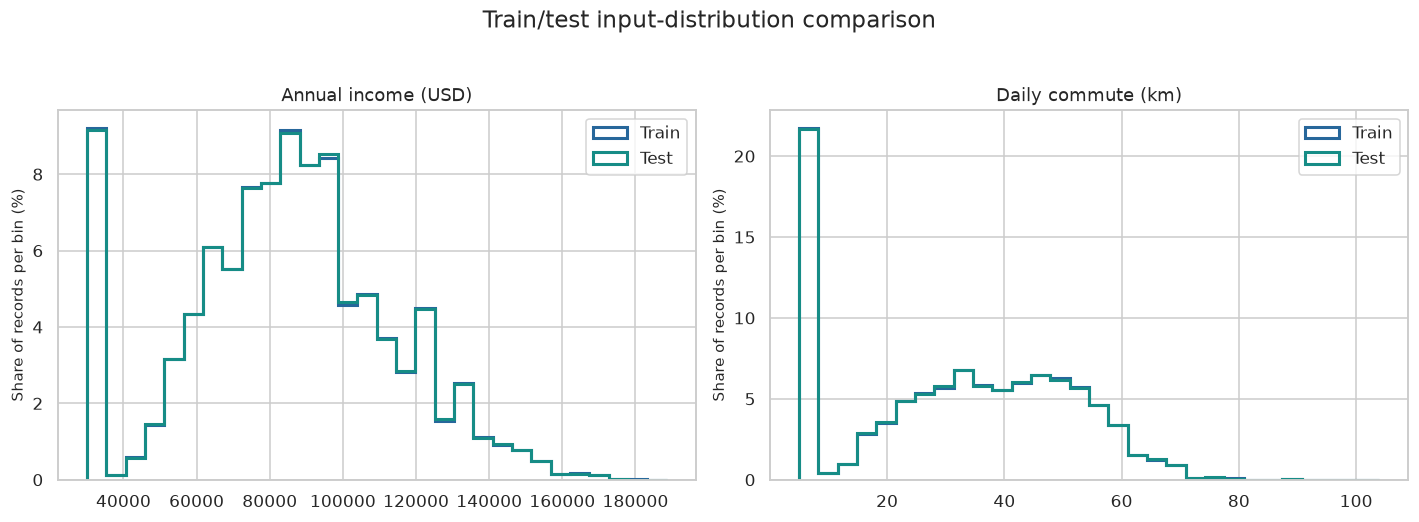

**Takeaway:** the largest absolute numeric standardized mean difference is 0.00475; the largest category-share gap is 0.171 percentage points. The observed category vocabularies match. The two test commutes beyond the training maximum are retained. These checks describe input compatibility, not out-of-sample prediction accuracy.

In [16]:
shift_rows = []
for column in NUMERIC:
    train_values, test_values = train_clean[column], test_clean[column]
    pooled_sd = np.sqrt((train_values.var(ddof=1) + test_values.var(ddof=1)) / 2)
    standardized_difference = (test_values.mean() - train_values.mean()) / pooled_sd
    shift_rows.append({
        "Feature": column, "Train mean": train_values.mean(), "Test mean": test_values.mean(),
        "Standardized mean difference": standardized_difference,
        "Test below observed train minimum": int(test_values.lt(train_values.min()).sum()),
        "Test above observed train maximum": int(test_values.gt(train_values.max()).sum()),
    })
numeric_shift = pd.DataFrame(shift_rows)
numeric_shift.to_csv(TABLES / "train_test_numeric_comparison.csv", index=False)
show_table(numeric_shift, 5)

category_shift_rows = []
for column, order in CATEGORY_ORDER.items():
    train_share = train_clean[column].value_counts(normalize=True).reindex(order, fill_value=0)
    test_share = test_clean[column].value_counts(normalize=True).reindex(order, fill_value=0)
    for category in order:
        category_shift_rows.append({
            "Feature": column, "Category": category,
            "Train share (%)": train_share[category]*100,
            "Test share (%)": test_share[category]*100,
            "Difference (percentage points)": (test_share[category]-train_share[category])*100,
        })
category_shift = pd.DataFrame(category_shift_rows)
category_shift.to_csv(TABLES / "train_test_categorical_comparison.csv", index=False)
show_table(category_shift)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, column in zip(axes, ["Annual_Income_USD", "Daily_Commute_km"]):
    minimum = min(train_clean[column].min(), test_clean[column].min())
    maximum = max(train_clean[column].max(), test_clean[column].max())
    bins = np.linspace(minimum, maximum, 31)
    for frame, label, color in [(train_clean, "Train", BLUE), (test_clean, "Test", TEAL)]:
        ax.hist(frame[column], bins=bins, weights=np.full(len(frame), 100/len(frame)),
                histtype="step", linewidth=2, label=label, color=color)
    ax.set_title(titles[column])
    ax.set_ylabel("Share of records per bin (%)")
    ax.legend()
fig.suptitle("Train/test input-distribution comparison", fontsize=15)
fig.tight_layout(rect=[0, 0, 1, 0.94])
save_figure(fig, "08_train_test_comparison.png")

max_smd = numeric_shift["Standardized mean difference"].abs().max()
max_category_gap = category_shift["Difference (percentage points)"].abs().max()
display(Markdown(
    f"**Takeaway:** the largest absolute numeric standardized mean difference is "
    f"{max_smd:.5f}; the largest category-share gap is {max_category_gap:.3f} "
    "percentage points. The observed category vocabularies match. The two test "
    "commutes beyond the training maximum are retained. These checks describe "
    "input compatibility, not out-of-sample prediction accuracy."
))

## 12. Verify the exports and preserve provenance

We read the processed files back, confirm the target mapping and retained
predictor values, and verify that every raw file still has its original SHA-256
hash. The manifest records the input snapshot and analysis-library versions.

In [17]:
train_export = pd.read_csv(PROCESSED / "train_clean.csv")
test_export = pd.read_csv(PROCESSED / "test_clean.csv")
pd.testing.assert_frame_equal(train_export, train_clean)
pd.testing.assert_frame_equal(test_export, test_clean)
assert train_export["id"].is_unique and test_export["id"].is_unique
assert TARGET not in test_export
assert len(FEATURES) == 13 and "id" not in FEATURES and TARGET not in FEATURES
assert {name: sha256_file(ROOT / name) for name in raw_frames} == raw_hashes

manifest = {
    "analysis_date": "2026-10-09",
    "competition": "playground-series-s6e9",
    "source_url": "https://www.kaggle.com/competitions/playground-series-s6e9",
    "raw_files_sha256": raw_hashes,
    "processed_files": {
        "data/processed/train_clean.csv": {
            "rows": len(train_export), "columns": train_export.shape[1],
            "sha256": sha256_file(PROCESSED / "train_clean.csv"),
        },
        "data/processed/test_clean.csv": {
            "rows": len(test_export), "columns": test_export.shape[1],
            "sha256": sha256_file(PROCESSED / "test_clean.csv"),
        },
    },
    "target_mapping": TARGET_MAPPING,
    "predictor_columns": FEATURES,
    "rows_removed": 0,
    "numeric_or_categorical_predictor_values_changed": 0,
    "predictive_model_trained": False,
    "python": platform.python_version(),
    "library_versions": versions,
}
(ROOT / "docs" / "reports" / "data_manifest.json").write_text(json.dumps(manifest, indent=2))

verification = pd.DataFrame([
    {"Check": "Raw files unchanged", "Result": "Confirmed by SHA-256"},
    {"Check": "Processed CSV round trip", "Result": "Exact dataframe match"},
    {"Check": "Rows removed or imputed", "Result": "0"},
    {"Check": "Predictor values modified", "Result": "0"},
    {"Check": "Train target coding", "Result": "No=0; Yes=1"},
    {"Check": "Test outcome", "Result": "Remains absent"},
    {"Check": "Models trained", "Result": "None"},
])
show_table(verification)
del train_export, test_export

Check,Result
Raw files unchanged,Confirmed by SHA-256
Processed CSV round trip,Exact dataframe match
Rows removed or imputed,0
Predictor values modified,0
Train target coding,No=0; Yes=1
Test outcome,Remains absent
Models trained,None


## 13. What we understand now

### Supported observations

- The three files have different roles: labeled training data, unlabeled prediction
  inputs, and a submission-format example.
- The feature set describes synthetic customer profiles, commuting, vehicle
  ownership, charging access, concern codes, subsidy availability, and range anxiety.
- The supplied target is imbalanced. A majority-only rule gives high accuracy but
  detects no Yes labels.
- The audited files require no row deletion, imputation, or correction of observed
  predictor values. Integer storage and target coding are documented separately.
- Subsidy availability, charging possibility, anxiety categories, concern codes,
  and income groups show descriptive patterns worth evaluating in a classifier.
- Rare-category counts matter. Train/test input summaries are close, with a small
  number of test values outside the observed training range.

### Limits of these conclusions

The data are synthetic and do not establish a representative dealership customer
population. There is no documented purchase horizon, campaign response, actual
transaction value, subsidy amount, named location, or collection date. We cannot
estimate actual campaign ROI or causal effects from these files. EDA relationships
are not a substitute for validation, calibrated predictions, or independent
business evidence.

### Student discussion prompts

1. Why is prioritization a useful business question when sales contact capacity is limited?
2. Why were statistical outliers retained instead of automatically removed?
3. Which descriptive relationship is most worth testing, and what could confound it?
4. What additional real-world information would be needed to interpret the label as
   the dealership's desired outcome?

## 14. Next phase: modeling and validation

Before model experiments, establish a reproducible validation plan within the
labeled training file and keep learned preprocessing inside training folds.
Compare a simple baseline with course-aligned classifiers such as logistic
regression and decision trees. Evaluate ROC-AUC, precision/recall, and how strongly
the ranked list concentrates Yes labels within a fixed contact capacity. If the
application displays probabilities, inspect calibration as well.

Gender remains a documented candidate variable; its necessity and subgroup
performance should be considered before final model inclusion. No feature has
been selected merely because of an EDA correlation.

Deployment, monitoring, and the customer-prioritization interface belong to later
capstone phases. This notebook establishes the data understanding and preparation
on which those decisions will depend.